# 03 — KPI Analysis | DIET Customer Escalation Risk Hackathon

**Owner:** Member 2 — KPI Analysis  
**Repository destination:** `notebooks/03_kpi_analysis.ipynb`  
**Input:** `customer_support_tickets.csv`  
**Output:** reusable KPI tables in `outputs/member2/`

This notebook is self-contained: it loads the supplied CSV, performs conservative data validation and cleaning (the upstream Member 1 preparation needed to make this notebook runnable on its own), and then calculates Member 2's supported KPIs.

### Important analytical rules

- A ticket count is not an escalation count. An escalation rate is **not calculated** unless the CSV contains an explicit escalation indicator.
- Status and priority distributions are workload measures, not escalation outcomes.
- A timestamp is not automatically a duration. First-response and resolution durations require a genuine ticket-created timestamp, which is not present in the supplied CSV.
- CSAT statistics use only valid recorded ratings. No low-CSAT threshold is invented.
- Missing values are not imputed. Exact duplicate rows may be removed; conflicting duplicate ticket IDs are reported and excluded from ticket-level KPI denominators rather than silently discarded.

**Run this notebook from top to bottom (Run All).**

## 1. Imports and project paths

The CSV is searched for in common project locations, including `data/raw/`, the project root, and the notebook's current working directory. No teammate-specific absolute path is required.

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda value: f"{value:,.2f}")

DATA_FILENAME = "customer_support_tickets.csv"

# Search current directory and its parents so the notebook works whether
# Jupyter was launched from the repository root or from the notebooks folder.
search_bases = [Path.cwd(), *Path.cwd().parents]
candidate_paths = []
for base in search_bases:
    candidate_paths.extend([
        base / "data" / "raw" / DATA_FILENAME,
        base / "data" / "processed" / DATA_FILENAME,
        base / DATA_FILENAME,
    ])

# Also support the execution environment used to prepare this notebook.
candidate_paths.append(Path("/mnt/data") / DATA_FILENAME)

seen = set()
candidate_paths = [p for p in candidate_paths if not (str(p.resolve()) in seen or seen.add(str(p.resolve())))]
DATA_PATH = next((p for p in candidate_paths if p.is_file()), None)

if DATA_PATH is None:
    searched = "\n".join(f"- {p}" for p in candidate_paths)
    raise FileNotFoundError(
        f"Could not find {DATA_FILENAME}. Place it in data/raw/ or the project root.\n"
        f"Locations checked:\n{searched}"
    )

# Treat the directory containing data/raw/ as the project root when possible.
PROJECT_ROOT = DATA_PATH.parent.parent.parent if DATA_PATH.parent.name == "raw" and DATA_PATH.parent.parent.name == "data" else DATA_PATH.parent
OUTPUT_DIR = PROJECT_ROOT / "outputs" / "member2"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print(f"Dataset found: {DATA_PATH.name}")
print(f"Project/output directory: {PROJECT_ROOT}")
print(f"Aggregated outputs will be saved to: {OUTPUT_DIR}")

Dataset found: customer_support_tickets.csv
Project/output directory: /mnt/data
Aggregated outputs will be saved to: /mnt/data/outputs/member2


## 2. Load the raw CSV and confirm the real schema

The notebook does not assume that fields exist just because they appear in the challenge guide. The actual CSV schema is checked first. The preview excludes customer names, email addresses, and free-text descriptions.

In [2]:
raw_df = pd.read_csv(DATA_PATH)

print(f"Raw dataset shape: {raw_df.shape[0]:,} rows × {raw_df.shape[1]:,} columns")
print("\nColumn names:")
for column in raw_df.columns:
    print(f"- {column}")

schema_report = pd.DataFrame({
    "column": raw_df.columns,
    "dtype": [str(dtype) for dtype in raw_df.dtypes],
    "non_null_count": [int(raw_df[column].notna().sum()) for column in raw_df.columns],
    "missing_count": [int(raw_df[column].isna().sum()) for column in raw_df.columns],
    "unique_non_null": [int(raw_df[column].nunique(dropna=True)) for column in raw_df.columns],
})
display(schema_report)

safe_preview_columns = [
    "Ticket ID", "Customer Age", "Customer Gender", "Product Purchased",
    "Date of Purchase", "Ticket Type", "Ticket Status", "Ticket Priority",
    "Ticket Channel", "First Response Time", "Time to Resolution",
    "Customer Satisfaction Rating",
]
safe_preview_columns = [column for column in safe_preview_columns if column in raw_df.columns]
display(raw_df[safe_preview_columns].head(8))

Raw dataset shape: 8,469 rows × 17 columns

Column names:
- Ticket ID
- Customer Name
- Customer Email
- Customer Age
- Customer Gender
- Product Purchased
- Date of Purchase
- Ticket Type
- Ticket Subject
- Ticket Description
- Ticket Status
- Resolution
- Ticket Priority
- Ticket Channel
- First Response Time
- Time to Resolution
- Customer Satisfaction Rating


,column,dtype,non_null_count,missing_count,unique_non_null
0,Ticket ID,int64,8469,0,8469
1,Customer Name,object,8469,0,8028
2,Customer Email,object,8469,0,8320
3,Customer Age,int64,8469,0,53
4,Customer Gender,object,8469,0,3
5,Product Purchased,object,8469,0,42
6,Date of Purchase,object,8469,0,730
7,Ticket Type,object,8469,0,5
8,Ticket Subject,object,8469,0,16
9,Ticket Description,object,8469,0,8077


,Ticket ID,Customer Age,Customer Gender,Product Purchased,Date of Purchase,Ticket Type,Ticket Status,Ticket Priority,Ticket Channel,First Response Time,Time to Resolution,Customer Satisfaction Rating
0,1,32,Other,GoPro Hero,2021-03-22,Technical issue,Pending Customer Response,Critical,Social media,2023-06-01 12:15:36,NaN,NaN
1,2,42,Female,LG Smart TV,2021-05-22,Technical issue,Pending Customer Response,Critical,Chat,2023-06-01 16:45:38,NaN,NaN
2,3,48,Other,Dell XPS,2020-07-14,Technical issue,Closed,Low,Social media,2023-06-01 11:14:38,2023-06-01 18:05:38,3.00
3,4,27,Female,Microsoft Office,2020-11-13,Billing inquiry,Closed,Low,Social media,2023-06-01 07:29:40,2023-06-01 01:57:40,3.00
4,5,67,Female,Autodesk AutoCAD,2020-02-04,Billing inquiry,Closed,Low,Email,2023-06-01 00:12:42,2023-06-01 19:53:42,1.00
5,6,53,Male,Microsoft Office,2020-07-28,Cancellation request,Open,Low,Social media,NaN,NaN,NaN
6,7,24,Other,Microsoft Surface,2020-02-23,Product inquiry,Open,Critical,Social media,NaN,NaN,NaN
7,8,23,Male,Philips Hue Lights,2020-08-09,Refund request,Open,Critical,Social media,NaN,NaN,NaN


## 3. Raw data-quality audit (Member 1 handoff checks)

These checks are performed before cleaning so that the original condition of the supplied file is visible. Missing `Resolution`, `First Response Time`, `Time to Resolution`, and CSAT values may be structurally associated with ticket status; they are not automatically errors and will not be filled with invented values.

In [3]:
raw_missing = pd.DataFrame({
    "field": raw_df.columns,
    "missing_count": [int(raw_df[column].isna().sum()) for column in raw_df.columns],
})
raw_missing["missing_pct"] = np.where(
    len(raw_df) > 0, raw_missing["missing_count"] / len(raw_df) * 100, np.nan
)
raw_missing = raw_missing.sort_values(["missing_count", "field"], ascending=[False, True]).reset_index(drop=True)

raw_quality_summary = pd.DataFrame([
    {"check": "Raw rows", "value": len(raw_df)},
    {"check": "Raw columns", "value": raw_df.shape[1]},
    {"check": "Exact duplicate rows", "value": int(raw_df.duplicated().sum())},
    {"check": "Missing Ticket IDs", "value": int(raw_df["Ticket ID"].isna().sum()) if "Ticket ID" in raw_df.columns else np.nan},
    {"check": "Rows involved in duplicate Ticket IDs", "value": int(raw_df.loc[raw_df["Ticket ID"].notna(), "Ticket ID"].duplicated(keep=False).sum()) if "Ticket ID" in raw_df.columns else np.nan},
])

display(raw_quality_summary)
display(raw_missing)

if "Ticket Status" in raw_df.columns:
    print("Observed Ticket Status values:")
    display(raw_df["Ticket Status"].value_counts(dropna=False).rename_axis("Ticket Status").reset_index(name="ticket_count"))
if "Ticket Priority" in raw_df.columns:
    print("Observed Ticket Priority values:")
    display(raw_df["Ticket Priority"].value_counts(dropna=False).rename_axis("Ticket Priority").reset_index(name="ticket_count"))

,check,value
0,Raw rows,8469
1,Raw columns,17
2,Exact duplicate rows,0
3,Missing Ticket IDs,0
4,Rows involved in duplicate Ticket IDs,0


,field,missing_count,missing_pct
0,Customer Satisfaction Rating,5700,67.30
1,Resolution,5700,67.30
2,Time to Resolution,5700,67.30
3,First Response Time,2819,33.29
4,Customer Age,0,0.00
5,Customer Email,0,0.00
6,Customer Gender,0,0.00
7,Customer Name,0,0.00
8,Date of Purchase,0,0.00
9,Product Purchased,0,0.00


Observed Ticket Status values:


,Ticket Status,ticket_count
0,Pending Customer Response,2881
1,Open,2819
2,Closed,2769


Observed Ticket Priority values:


,Ticket Priority,ticket_count
0,Medium,2192
1,Critical,2129
2,High,2085
3,Low,2063


## 4. Conservative cleaning and validation (Member 1 preparation)

The cleaning function below is embedded in this notebook so this single file can run without a separate Python module. It applies only defensible changes:

1. trims leading/trailing whitespace and converts blank text to missing;
2. parses known numeric and date/time fields;
3. flags ages outside a broad 0–120 range and CSAT ratings outside 1–5;
4. standardises recognised category spelling/case only;
5. removes only completely identical rows;
6. retains conflicting duplicate Ticket IDs for review and reports them;
7. flags response/resolution timestamp-order anomalies without changing the original event timestamps;
8. never imputes missing values or fabricates a field.

When Member 1's reviewed `src/processing/data_cleaner.py` is available in the repository, the team can replace the one call in Section 5 with that approved function.

In [4]:
CATEGORY_DOMAINS = {
    "Ticket Status": ["Closed", "Open", "Pending Customer Response"],
    "Ticket Priority": ["Critical", "High", "Medium", "Low"],
    "Ticket Channel": ["Chat", "Email", "Phone", "Social media"],
    "Ticket Type": [
        "Billing inquiry", "Cancellation request", "Product inquiry",
        "Refund request", "Technical issue",
    ],
    "Customer Gender": ["Female", "Male", "Other"],
}
NUMERIC_COLUMNS = ["Ticket ID", "Customer Age", "Customer Satisfaction Rating"]
DATETIME_COLUMNS = ["Date of Purchase", "First Response Time", "Time to Resolution"]


def clean_support_tickets_in_notebook(raw_data: pd.DataFrame):
    """Return (cleaned_df, quality_report) using conservative, auditable rules."""
    if not isinstance(raw_data, pd.DataFrame):
        raise TypeError("raw_data must be a pandas DataFrame")
    if raw_data.columns.duplicated().any():
        duplicate_columns = raw_data.columns[raw_data.columns.duplicated()].tolist()
        raise ValueError(f"Duplicate column names must be resolved first: {duplicate_columns}")

    cleaned = raw_data.copy(deep=True)
    rows_before = int(len(cleaned))
    cleaning_log = []

    # 1) Normalise whitespace and blank text values.
    for column in cleaned.select_dtypes(include=["object", "string"]).columns:
        before = cleaned[column].astype("string")
        trimmed = before.str.strip()
        changed = int((before.notna() & trimmed.ne(before)).sum())
        blank_count = int(trimmed.eq("").fillna(False).sum())
        cleaned[column] = trimmed.mask(trimmed.eq(""), pd.NA)
        if changed:
            cleaning_log.append({
                "field": column, "action": "Trimmed leading/trailing whitespace",
                "affected": changed, "reason": "Formatting-only correction; meaning is preserved."
            })
        if blank_count:
            cleaning_log.append({
                "field": column, "action": "Converted blank strings to missing",
                "affected": blank_count, "reason": "Blank text is represented consistently; no value is invented."
            })

    # 2) Convert numeric fields without guessing values.
    for column in NUMERIC_COLUMNS:
        if column not in cleaned.columns:
            continue
        before = cleaned[column].copy()
        parsed = pd.to_numeric(before, errors="coerce")
        failed = int((before.notna() & parsed.isna()).sum())
        cleaned[column] = parsed
        if failed:
            cleaning_log.append({
                "field": column, "action": "Unparseable numeric values set to missing",
                "affected": failed, "reason": "Non-numeric values cannot be used in numeric KPI calculations."
            })

    # 3) Parse date/timestamp columns. These remain event timestamps, not durations.
    timestamp_parse_rows = []
    for column in DATETIME_COLUMNS:
        if column not in cleaned.columns:
            continue
        before = cleaned[column].copy()
        parsed = pd.to_datetime(before, errors="coerce")
        failed = int((before.notna() & parsed.isna()).sum())
        timestamp_parse_rows.append({
            "field": column,
            "raw_non_missing": int(before.notna().sum()),
            "parsed_successfully": int(parsed.notna().sum()),
            "unparseable_non_missing": failed,
            "missing_after_parse": int(parsed.isna().sum()),
        })
        cleaned[column] = parsed
        if failed:
            cleaning_log.append({
                "field": column, "action": "Unparseable timestamps set to NaT",
                "affected": failed, "reason": "Malformed time values are not inferred."
            })

    # 4) Apply broad validity checks only to the appropriate numeric fields.
    if "Customer Age" in cleaned.columns:
        invalid_age = cleaned["Customer Age"].notna() & ~cleaned["Customer Age"].between(0, 120)
        if int(invalid_age.sum()):
            count = int(invalid_age.sum())
            cleaned.loc[invalid_age, "Customer Age"] = np.nan
            cleaning_log.append({
                "field": "Customer Age", "action": "Out-of-range ages set to missing",
                "affected": count, "reason": "Broad validity range applied: 0–120; values are not clipped."
            })

    if "Customer Satisfaction Rating" in cleaned.columns:
        invalid_csat = cleaned["Customer Satisfaction Rating"].notna() & ~cleaned["Customer Satisfaction Rating"].between(1, 5)
        if int(invalid_csat.sum()):
            count = int(invalid_csat.sum())
            cleaned.loc[invalid_csat, "Customer Satisfaction Rating"] = np.nan
            cleaning_log.append({
                "field": "Customer Satisfaction Rating", "action": "Out-of-range CSAT ratings set to missing",
                "affected": count, "reason": "Observed rating scale is 1–5; invalid ratings are not clipped."
            })

    # 5) Map only recognised categories that match after case-folding.
    category_audit_rows = []
    for column, allowed_values in CATEGORY_DOMAINS.items():
        if column not in cleaned.columns:
            continue
        mapping = {value.casefold(): value for value in allowed_values}
        current = cleaned[column].astype("string")
        mapped = current.str.casefold().map(mapping)
        known = current.notna() & mapped.notna()
        changed = int((known & current.ne(mapped)).sum())
        if changed:
            cleaned.loc[known, column] = mapped.loc[known]
            cleaning_log.append({
                "field": column, "action": "Standardised recognised category spelling/case",
                "affected": changed, "reason": "Only recognised labels were mapped to the documented spelling."
            })
        unexpected = sorted(current.loc[current.notna() & mapped.isna()].unique().tolist())
        category_audit_rows.append({
            "field": column,
            "distinct_non_missing_values": int(cleaned[column].nunique(dropna=True)),
            "unexpected_values": unexpected,
            "unexpected_value_count": len(unexpected),
        })

    # 6) Remove only completely identical records.
    exact_duplicates_found = int(cleaned.duplicated(keep="first").sum())
    if exact_duplicates_found:
        cleaned = cleaned.drop_duplicates(keep="first").copy()
        cleaning_log.append({
            "field": "Entire row", "action": "Removed fully identical duplicate rows",
            "affected": exact_duplicates_found,
            "reason": "Exact copies add no distinct ticket information. Conflicting IDs are retained."
        })

    # 7) Surface missing and conflicting IDs; do not silently delete conflicting IDs.
    missing_ids = int(cleaned["Ticket ID"].isna().sum()) if "Ticket ID" in cleaned.columns else None
    duplicate_id_mask = (
        cleaned["Ticket ID"].notna() & cleaned["Ticket ID"].duplicated(keep=False)
        if "Ticket ID" in cleaned.columns else pd.Series(False, index=cleaned.index)
    )
    duplicate_id_rows = int(duplicate_id_mask.sum())
    duplicate_id_table = cleaned.loc[duplicate_id_mask].copy() if duplicate_id_rows else pd.DataFrame()
    if not duplicate_id_table.empty:
        duplicate_id_table = duplicate_id_table.drop(
            columns=[c for c in ["Customer Name", "Customer Email", "Ticket Description"] if c in duplicate_id_table.columns]
        )

    # 8) Chronology audit: flag only; this is not a response/resolution duration.
    timestamp_order_rows = []
    if {"First Response Time", "Time to Resolution"}.issubset(cleaned.columns):
        first = pd.to_datetime(cleaned["First Response Time"], errors="coerce")
        resolution_event = pd.to_datetime(cleaned["Time to Resolution"], errors="coerce")
        paired = first.notna() & resolution_event.notna()
        before = paired & resolution_event.lt(first)
        equal = paired & resolution_event.eq(first)
        after = paired & resolution_event.gt(first)
        pair_count = int(paired.sum())
        timestamp_order_rows.append({
            "paired_timestamp_records": pair_count,
            "resolution_before_first_response": int(before.sum()),
            "same_timestamp": int(equal.sum()),
            "resolution_after_first_response": int(after.sum()),
            "before_response_pct_of_pairs": float(before.sum() / pair_count * 100) if pair_count else np.nan,
            "decision": "Flag only. Do not overwrite timestamps or treat them as elapsed durations."
        })

    missing_table = pd.DataFrame({
        "field": cleaned.columns,
        "missing_count": [int(cleaned[column].isna().sum()) for column in cleaned.columns],
    })
    missing_table["missing_pct"] = np.where(
        len(cleaned) > 0, missing_table["missing_count"] / len(cleaned) * 100, np.nan
    )
    missing_table = missing_table.sort_values(["missing_count", "field"], ascending=[False, True]).reset_index(drop=True)

    quality_summary = pd.DataFrame([
        {"check": "Rows before cleaning", "value": rows_before},
        {"check": "Rows after cleaning", "value": int(len(cleaned))},
        {"check": "Exact duplicate rows found and removed", "value": exact_duplicates_found},
        {"check": "Missing Ticket IDs", "value": missing_ids},
        {"check": "Rows involved in duplicate Ticket IDs (retained for review)", "value": duplicate_id_rows},
    ])

    quality_report = {
        "summary": quality_summary,
        "missing_values": missing_table,
        "cleaning_log": pd.DataFrame(cleaning_log, columns=["field", "action", "affected", "reason"]),
        "category_audit": pd.DataFrame(category_audit_rows),
        "duplicate_ticket_ids": duplicate_id_table,
        "timestamp_parse": pd.DataFrame(timestamp_parse_rows),
        "timestamp_order": pd.DataFrame(timestamp_order_rows),
    }
    return cleaned, quality_report

# One call creates the cleaned DataFrame that Member 2 uses below.
df_clean, quality_report = clean_support_tickets_in_notebook(raw_df)

print(f"Cleaned shape: {df_clean.shape[0]:,} rows × {df_clean.shape[1]:,} columns")
print("Data cleaning completed. No missing values were imputed.")
display(quality_report["summary"])
display(quality_report["cleaning_log"])
display(quality_report["category_audit"])
display(quality_report["missing_values"])
if not quality_report["duplicate_ticket_ids"].empty:
    print("Conflicting duplicate Ticket IDs require Member 1 review:")
    display(quality_report["duplicate_ticket_ids"].head(20))

Cleaned shape: 8,469 rows × 17 columns
Data cleaning completed. No missing values were imputed.


,check,value
0,Rows before cleaning,8469
1,Rows after cleaning,8469
2,Exact duplicate rows found and removed,0
3,Missing Ticket IDs,0
4,Rows involved in duplicate Ticket IDs (retaine...,0


,field,action,affected,reason


,field,distinct_non_missing_values,unexpected_values,unexpected_value_count
0,Ticket Status,3,[],0
1,Ticket Priority,4,[],0
2,Ticket Channel,4,[],0
3,Ticket Type,5,[],0
4,Customer Gender,3,[],0


,field,missing_count,missing_pct
0,Customer Satisfaction Rating,5700,67.30
1,Resolution,5700,67.30
2,Time to Resolution,5700,67.30
3,First Response Time,2819,33.29
4,Customer Age,0,0.00
5,Customer Email,0,0.00
6,Customer Gender,0,0.00
7,Customer Name,0,0.00
8,Date of Purchase,0,0.00
9,Product Purchased,0,0.00


## 5. Define the KPI-eligible ticket population

A ticket must have a non-missing, unique `Ticket ID` to enter the ticket-level KPI denominator. Conflicting duplicate IDs are retained in `df_clean` for data-quality review but are excluded from KPI calculations until reconciled. Exact duplicate rows have already been removed by the cleaning step.

In [5]:
if "Ticket ID" not in df_clean.columns:
    raise KeyError("The supplied dataset does not contain the required 'Ticket ID' field.")

missing_id_mask = df_clean["Ticket ID"].isna()
duplicate_id_mask = df_clean["Ticket ID"].notna() & df_clean["Ticket ID"].duplicated(keep=False)
valid_ticket_mask = ~missing_id_mask & ~duplicate_id_mask

df_kpi = df_clean.loc[valid_ticket_mask].copy()
TOTAL_TICKETS = int(df_kpi["Ticket ID"].nunique(dropna=True))

population_audit = pd.DataFrame([
    {"population_item": "Rows in cleaned DataFrame", "ticket_count": int(len(df_clean))},
    {"population_item": "Missing Ticket ID rows excluded from KPI population", "ticket_count": int(missing_id_mask.sum())},
    {"population_item": "Rows with conflicting duplicate Ticket IDs excluded pending review", "ticket_count": int(duplicate_id_mask.sum())},
    {"population_item": "KPI-eligible unique tickets", "ticket_count": TOTAL_TICKETS},
])
display(population_audit)
print(f"KPI denominator: {TOTAL_TICKETS:,} unique, non-null ticket IDs")

,population_item,ticket_count
0,Rows in cleaned DataFrame,8469
1,Missing Ticket ID rows excluded from KPI popul...,0
2,Rows with conflicting duplicate Ticket IDs exc...,0
3,KPI-eligible unique tickets,8469


KPI denominator: 8,469 unique, non-null ticket IDs


## 6. KPI calculation function (Member 2)

`calculate_kpis()` accepts the cleaned DataFrame and returns a dictionary of DataFrames. Each KPI has a clear definition and numerator/denominator where applicable. The function reports only metrics supported by the actual dataset.

In [6]:
def calculate_kpis(cleaned_df: pd.DataFrame) -> dict:
    """Calculate supported Member 2 KPIs from a cleaned support-ticket DataFrame."""
    if not isinstance(cleaned_df, pd.DataFrame):
        raise TypeError("cleaned_df must be a pandas DataFrame")
    if "Ticket ID" not in cleaned_df.columns:
        raise KeyError("Ticket ID is required for ticket-level KPI calculations.")

    source = cleaned_df.copy()
    missing_id = source["Ticket ID"].isna()
    duplicate_id = source["Ticket ID"].notna() & source["Ticket ID"].duplicated(keep=False)
    eligible = source.loc[~missing_id & ~duplicate_id].copy()
    total = int(eligible["Ticket ID"].nunique(dropna=True))

    overview_rows = []
    def add_metric(metric, value, unit, numerator, denominator, definition, availability="Available"):
        overview_rows.append({
            "metric": metric,
            "value": value,
            "unit": unit,
            "numerator": numerator,
            "denominator": denominator,
            "availability": availability,
            "definition": definition,
        })

    add_metric(
        "Total ticket volume", total, "tickets", total, "Not applicable",
        "Count of unique, non-null Ticket IDs after exact duplicate removal; conflicting duplicate IDs are excluded pending review."
    )

    status_distribution = pd.DataFrame()
    status_priority = pd.DataFrame()
    if "Ticket Status" in eligible.columns:
        status_values = eligible["Ticket Status"].astype("string").fillna("<Missing>")
        status_counts = status_values.value_counts(dropna=False).rename_axis("Ticket Status").reset_index(name="ticket_count")
        status_counts["pct_of_eligible_tickets"] = np.where(
            total > 0, status_counts["ticket_count"] / total * 100, np.nan
        )
        status_distribution = status_counts.sort_values("ticket_count", ascending=False).reset_index(drop=True)

        closed_labels = {"closed"}
        unresolved_labels = {"open", "pending customer response"}
        status_normalised = eligible["Ticket Status"].astype("string").str.strip().str.casefold()
        closed_count = int(status_normalised.isin(closed_labels).sum())
        open_count = int(status_normalised.eq("open").sum())
        pending_count = int(status_normalised.eq("pending customer response").sum())
        unresolved_count = int(status_normalised.isin(unresolved_labels).sum())

        add_metric("Closed tickets", closed_count, "tickets", closed_count, total,
                   "Tickets whose Ticket Status is 'Closed'.")
        add_metric("Open tickets", open_count, "tickets", open_count, total,
                   "Tickets whose Ticket Status is 'Open'.")
        add_metric("Pending customer response tickets", pending_count, "tickets", pending_count, total,
                   "Tickets whose Ticket Status is 'Pending Customer Response'.")
        add_metric("Unresolved status workload", unresolved_count, "tickets", unresolved_count, total,
                   "Open plus Pending Customer Response tickets. Status-based outstanding workload at the data snapshot; no age threshold is available.")
        add_metric("Unresolved status workload rate", (unresolved_count / total * 100) if total else np.nan, "%",
                   unresolved_count, total,
                   "Unresolved status workload divided by all KPI-eligible tickets, multiplied by 100. This is not an escalation rate.")

    priority_distribution = pd.DataFrame()
    if "Ticket Priority" in eligible.columns:
        priority_values = eligible["Ticket Priority"].astype("string").fillna("<Missing>")
        priority_counts = priority_values.value_counts(dropna=False).rename_axis("Ticket Priority").reset_index(name="ticket_count")
        priority_counts["pct_of_eligible_tickets"] = np.where(
            total > 0, priority_counts["ticket_count"] / total * 100, np.nan
        )
        priority_distribution = priority_counts.sort_values("ticket_count", ascending=False).reset_index(drop=True)

    if {"Ticket Status", "Ticket Priority"}.issubset(eligible.columns):
        status_priority = pd.crosstab(
            eligible["Ticket Status"].fillna("<Missing>"),
            eligible["Ticket Priority"].fillna("<Missing>"),
            margins=True,
            margins_name="Total",
        )

    # CSAT: use valid recorded ratings only; no low-CSAT threshold is assumed.
    csat_distribution = pd.DataFrame()
    if "Customer Satisfaction Rating" in eligible.columns:
        csat_numeric = pd.to_numeric(eligible["Customer Satisfaction Rating"], errors="coerce")
        valid_csat = csat_numeric.between(1, 5, inclusive="both")
        csat_values = csat_numeric.loc[valid_csat].astype(float)
        if not csat_values.empty:
            rating_counts = csat_values.value_counts().sort_index().rename_axis("rating").reset_index(name="rated_tickets")
            rating_counts["pct_of_rated_tickets"] = rating_counts["rated_tickets"] / len(csat_values) * 100
            csat_distribution = rating_counts
            add_metric("Mean customer satisfaction", float(csat_values.mean()), "rating points",
                       float(csat_values.sum()), int(len(csat_values)),
                       "Arithmetic mean of valid recorded CSAT ratings (1–5); denominator is tickets with a valid recorded rating.")
            add_metric("Median customer satisfaction", float(csat_values.median()), "rating points",
                       "Median of valid recorded ratings", int(len(csat_values)),
                       "Median of valid recorded CSAT ratings (1–5).")
            add_metric("Tickets with recorded CSAT", int(len(csat_values)), "tickets",
                       int(len(csat_values)), total,
                       "Count of KPI-eligible tickets with a valid recorded CSAT rating.")
            add_metric("Recorded CSAT coverage", float(len(csat_values) / total * 100) if total else np.nan, "%",
                       int(len(csat_values)), total,
                       "Tickets with a valid recorded CSAT rating divided by all KPI-eligible tickets, multiplied by 100. This is coverage, not a satisfaction pass rate.")

    # Timestamp presence and consistency audit. Event timestamps are not elapsed durations.
    timestamp_fields = ["First Response Time", "Time to Resolution"]
    timestamp_rows = []
    parsed = {}
    for column in timestamp_fields:
        if column in eligible.columns:
            raw = eligible[column]
            parsed_values = pd.to_datetime(raw, errors="coerce")
            parsed[column] = parsed_values
            timestamp_rows.append({
                "field": column,
                "non_missing_values": int(raw.notna().sum()),
                "parsed_successfully": int(parsed_values.notna().sum()),
                "missing_or_unparseable": int(parsed_values.isna().sum()),
                "interpretation": "Event timestamp only; elapsed duration cannot be calculated without ticket creation time."
            })
    timestamp_audit = pd.DataFrame(timestamp_rows)

    timestamp_order_audit = pd.DataFrame()
    if set(timestamp_fields).issubset(parsed):
        first = parsed["First Response Time"]
        resolution_event = parsed["Time to Resolution"]
        paired = first.notna() & resolution_event.notna()
        before = paired & resolution_event.lt(first)
        equal = paired & resolution_event.eq(first)
        after = paired & resolution_event.gt(first)
        pair_count = int(paired.sum())
        timestamp_order_audit = pd.DataFrame([{
            "paired_records": pair_count,
            "resolution_timestamp_before_first_response": int(before.sum()),
            "same_timestamp": int(equal.sum()),
            "resolution_timestamp_after_first_response": int(after.sum()),
            "before_first_response_pct_of_pairs": float(before.sum() / pair_count * 100) if pair_count else np.nan,
        }])

    # Explicitly state metrics that cannot be calculated from the released columns.
    available_fields = set(eligible.columns)
    escalation_fields = [c for c in eligible.columns if "escalat" in c.casefold()]
    created_fields = [c for c in eligible.columns if any(token in c.casefold() for token in ["created", "opened", "ticket date"])]
    limitations = [
        {"metric_or_analysis": "Escalated ticket count / escalation rate", "status": "Unavailable", "reason": "No explicit escalation indicator field exists. Ticket Status and Ticket Priority are not valid substitutes." if not escalation_fields else f"Possible escalation field(s) require an approved data dictionary: {escalation_fields}."},
        {"metric_or_analysis": "First-response duration", "status": "Unavailable", "reason": "A genuine ticket-created timestamp is absent; First Response Time is an event timestamp, not elapsed time." if not created_fields else "Confirm the official created-time field definition before deriving duration."},
        {"metric_or_analysis": "Median / P90 resolution duration", "status": "Unavailable", "reason": "A genuine ticket-created timestamp and verified duration definition are absent; Time to Resolution is stored as a timestamp." if not created_fields else "Confirm the official created-time field and resolved-ticket eligibility rule before deriving duration."},
        {"metric_or_analysis": "SLA breach rate", "status": "Unavailable", "reason": "No SLA target, breach indicator, or eligible SLA population is supplied."},
        {"metric_or_analysis": "Low-CSAT rate", "status": "Unavailable", "reason": "No organiser-defined low-CSAT threshold is supplied. Mean, median, rating distribution, and recorded coverage are reported instead."},
        {"metric_or_analysis": "Age-based backlog / long-running rate", "status": "Unavailable", "reason": "No ticket-created timestamp or age threshold is supplied. Status-based unresolved workload is reported instead."},
        {"metric_or_analysis": "Ticket-created time trend", "status": "Unavailable", "reason": "Date of Purchase is not a ticket-created timestamp and must not be substituted for ticket creation time."},
    ]
    if not ({"Queue", "Department", "Support Queue"} & available_fields):
        limitations.append({"metric_or_analysis": "Queue-level KPI comparison", "status": "Unavailable", "reason": "No queue/department assignment field is present in the supplied schema."})
    limitations_df = pd.DataFrame(limitations)

    return {
        "overview": pd.DataFrame(overview_rows),
        "status_distribution": status_distribution,
        "priority_distribution": priority_distribution,
        "status_priority": status_priority,
        "csat_distribution": csat_distribution,
        "timestamp_audit": timestamp_audit,
        "timestamp_order_audit": timestamp_order_audit,
        "limitations": limitations_df,
    }


kpi_results = calculate_kpis(df_clean)
print("Member 2 KPI calculations completed.")
display(kpi_results["overview"])
display(kpi_results["limitations"])

Member 2 KPI calculations completed.


,metric,value,unit,numerator,denominator,availability,definition
0,Total ticket volume,"8,469.00",tickets,8469,Not applicable,Available,"Count of unique, non-null Ticket IDs after exa..."
1,Closed tickets,"2,769.00",tickets,2769,8469,Available,Tickets whose Ticket Status is 'Closed'.
2,Open tickets,"2,819.00",tickets,2819,8469,Available,Tickets whose Ticket Status is 'Open'.
3,Pending customer response tickets,"2,881.00",tickets,2881,8469,Available,Tickets whose Ticket Status is 'Pending Custom...
4,Unresolved status workload,"5,700.00",tickets,5700,8469,Available,Open plus Pending Customer Response tickets. S...
5,Unresolved status workload rate,67.30,%,5700,8469,Available,Unresolved status workload divided by all KPI-...
6,Mean customer satisfaction,2.99,rating points,"8,283.00",2769,Available,Arithmetic mean of valid recorded CSAT ratings...
7,Median customer satisfaction,3.00,rating points,Median of valid recorded ratings,2769,Available,Median of valid recorded CSAT ratings (1–5).
8,Tickets with recorded CSAT,"2,769.00",tickets,2769,8469,Available,Count of KPI-eligible tickets with a valid rec...
9,Recorded CSAT coverage,32.70,%,2769,8469,Available,Tickets with a valid recorded CSAT rating divi...


,metric_or_analysis,status,reason
0,Escalated ticket count / escalation rate,Unavailable,No explicit escalation indicator field exists....
1,First-response duration,Unavailable,A genuine ticket-created timestamp is absent; ...
2,Median / P90 resolution duration,Unavailable,A genuine ticket-created timestamp and verifie...
3,SLA breach rate,Unavailable,"No SLA target, breach indicator, or eligible S..."
4,Low-CSAT rate,Unavailable,No organiser-defined low-CSAT threshold is sup...
5,Age-based backlog / long-running rate,Unavailable,No ticket-created timestamp or age threshold i...
6,Ticket-created time trend,Unavailable,Date of Purchase is not a ticket-created times...
7,Queue-level KPI comparison,Unavailable,No queue/department assignment field is presen...


## 7. KPI tables and business definitions

The distribution percentages use the same denominator: all KPI-eligible unique tickets. CSAT rating percentages use only tickets with a valid recorded rating. These are different populations, so the denominators are shown explicitly.

In [7]:
print("Ticket status distribution")
display(kpi_results["status_distribution"])

print("Ticket priority distribution (workload mix only; not escalation risk)")
display(kpi_results["priority_distribution"])

print("Status × priority count matrix (descriptive workload table)")
display(kpi_results["status_priority"])

print("Customer satisfaction rating distribution")
display(kpi_results["csat_distribution"])

print("Timestamp availability audit")
display(kpi_results["timestamp_audit"])

print("Timestamp chronology consistency audit")
display(kpi_results["timestamp_order_audit"])

Ticket status distribution


,Ticket Status,ticket_count,pct_of_eligible_tickets
0,Pending Customer Response,2881,34.02
1,Open,2819,33.29
2,Closed,2769,32.70


Ticket priority distribution (workload mix only; not escalation risk)


,Ticket Priority,ticket_count,pct_of_eligible_tickets
0,Medium,2192,25.88
1,Critical,2129,25.14
2,High,2085,24.62
3,Low,2063,24.36


Status × priority count matrix (descriptive workload table)


...

,rating,rated_tickets,pct_of_rated_tickets
0,1.00,553,19.97
1,2.00,549,19.83
2,3.00,580,20.95
3,4.00,543,19.61
4,5.00,544,19.65


Timestamp availability audit


,field,non_missing_values,parsed_successfully,missing_or_unparseable,interpretation
0,First Response Time,5650,5650,2819,Event timestamp only; elapsed duration cannot ...
1,Time to Resolution,2769,2769,5700,Event timestamp only; elapsed duration cannot ...


Timestamp chronology consistency audit


,paired_records,resolution_timestamp_before_first_response,same_timestamp,resolution_timestamp_after_first_response,before_first_response_pct_of_pairs
0,2769,1365,2,1402,49.30


## 8. Decision-oriented visualisations

These charts show only supported measures: ticket status, priority workload, recorded CSAT ratings, and timestamp chronology. No escalation-rate or response/resolution-duration chart is created because those quantities are not supported by the supplied columns.

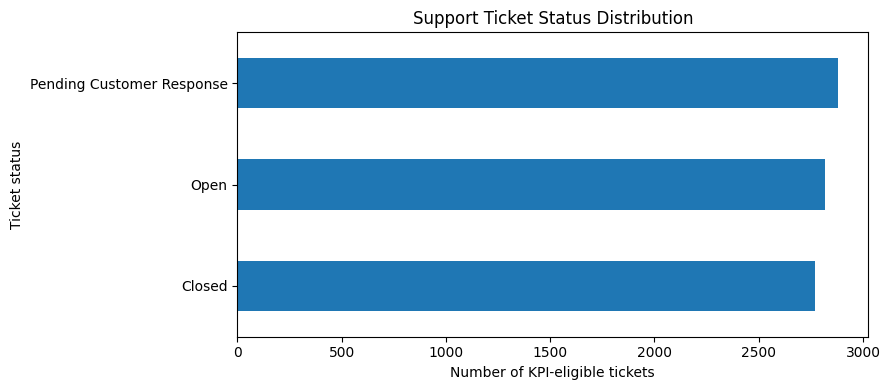

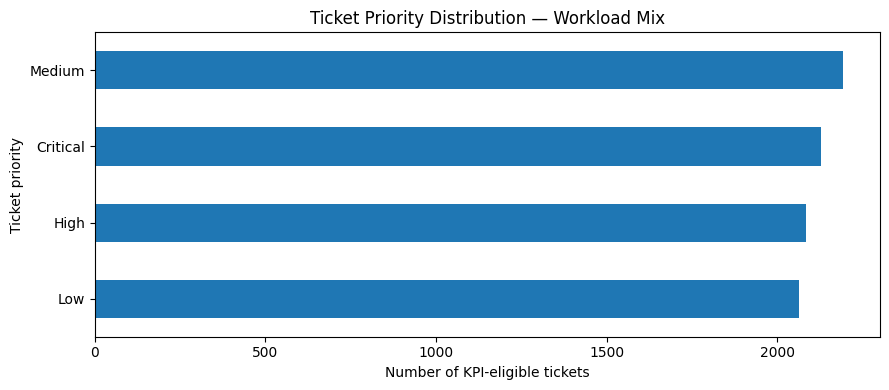

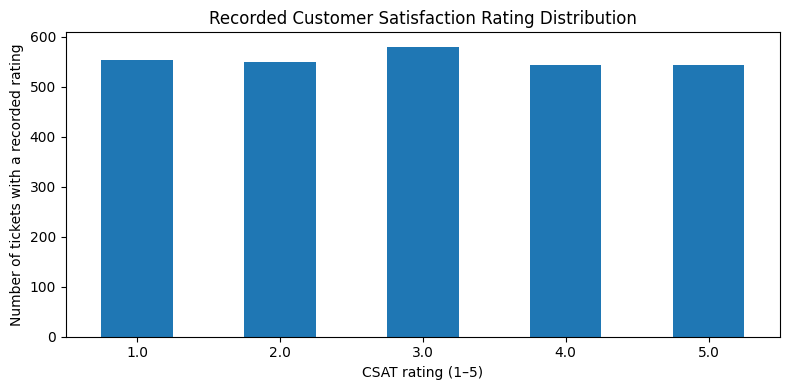

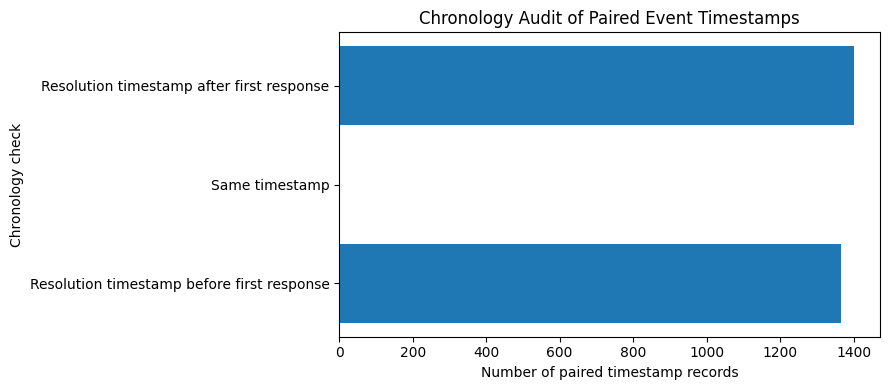

In [8]:
# Chart 1 — ticket status distribution
status_plot = kpi_results["status_distribution"].copy()
if not status_plot.empty:
    status_plot = status_plot.sort_values("ticket_count", ascending=True)
    ax = status_plot.plot.barh(x="Ticket Status", y="ticket_count", legend=False, figsize=(9, 4))
    ax.set_title("Support Ticket Status Distribution")
    ax.set_xlabel("Number of KPI-eligible tickets")
    ax.set_ylabel("Ticket status")
    plt.tight_layout()
    plt.show()

# Chart 2 — ticket priority distribution
priority_plot = kpi_results["priority_distribution"].copy()
if not priority_plot.empty:
    priority_plot = priority_plot.sort_values("ticket_count", ascending=True)
    ax = priority_plot.plot.barh(x="Ticket Priority", y="ticket_count", legend=False, figsize=(9, 4))
    ax.set_title("Ticket Priority Distribution — Workload Mix")
    ax.set_xlabel("Number of KPI-eligible tickets")
    ax.set_ylabel("Ticket priority")
    plt.tight_layout()
    plt.show()

# Chart 3 — observed CSAT rating distribution
csat_plot = kpi_results["csat_distribution"].copy()
if not csat_plot.empty:
    ax = csat_plot.plot.bar(x="rating", y="rated_tickets", legend=False, figsize=(8, 4))
    ax.set_title("Recorded Customer Satisfaction Rating Distribution")
    ax.set_xlabel("CSAT rating (1–5)")
    ax.set_ylabel("Number of tickets with a recorded rating")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

# Chart 4 — timestamp ordering check (not a duration chart)
order_plot = kpi_results["timestamp_order_audit"]
if not order_plot.empty:
    row = order_plot.iloc[0]
    labels = ["Resolution timestamp before first response", "Same timestamp", "Resolution timestamp after first response"]
    values = [row["resolution_timestamp_before_first_response"], row["same_timestamp"], row["resolution_timestamp_after_first_response"]]
    fig, ax = plt.subplots(figsize=(9, 4))
    ax.barh(labels, values)
    ax.set_title("Chronology Audit of Paired Event Timestamps")
    ax.set_xlabel("Number of paired timestamp records")
    ax.set_ylabel("Chronology check")
    plt.tight_layout()
    plt.show()

## 9. Automated validation and reconciliation

The assertions below independently reconcile the KPI outputs against the KPI-eligible DataFrame. They will fail loudly if a future dataset changes in a way that makes the current calculations inconsistent.

In [9]:
# Total ticket volume must equal the number of eligible unique ticket IDs.
reported_total = int(kpi_results["overview"].loc[
    kpi_results["overview"]["metric"].eq("Total ticket volume"), "value"
].iloc[0])
assert reported_total == int(df_kpi["Ticket ID"].nunique()) == TOTAL_TICKETS

# Status distribution and priority distribution must each reconcile to total eligible tickets.
if not kpi_results["status_distribution"].empty:
    assert int(kpi_results["status_distribution"]["ticket_count"].sum()) == TOTAL_TICKETS
if not kpi_results["priority_distribution"].empty:
    assert int(kpi_results["priority_distribution"]["ticket_count"].sum()) == TOTAL_TICKETS

# CSAT distribution must reconcile to the count of valid ratings.
if not kpi_results["csat_distribution"].empty:
    valid_csat_count = int(pd.to_numeric(df_kpi["Customer Satisfaction Rating"], errors="coerce").between(1, 5).sum())
    assert int(kpi_results["csat_distribution"]["rated_tickets"].sum()) == valid_csat_count

print("All KPI reconciliation checks passed.")
print(f"Validated ticket denominator: {TOTAL_TICKETS:,}")

All KPI reconciliation checks passed.
Validated ticket denominator: 8,469


## 10. Export integration-ready outputs

Only aggregate tables are exported. Customer names, email addresses, ticket descriptions, and other direct identifiers are not written to the outputs folder.

In [10]:
# Export the Member 1 quality audit tables.
quality_export_map = {
    "data_quality_summary.csv": quality_report["summary"],
    "missing_values.csv": quality_report["missing_values"],
    "cleaning_log.csv": quality_report["cleaning_log"],
    "category_audit.csv": quality_report["category_audit"],
    "timestamp_parse_audit.csv": quality_report["timestamp_parse"],
    "timestamp_order_audit.csv": quality_report["timestamp_order"],
}

# Export the Member 2 KPI tables.
kpi_export_map = {
    "kpi_overview.csv": kpi_results["overview"],
    "status_distribution.csv": kpi_results["status_distribution"],
    "priority_distribution.csv": kpi_results["priority_distribution"],
    "status_priority_crosstab.csv": kpi_results["status_priority"],
    "csat_distribution.csv": kpi_results["csat_distribution"],
    "timestamp_audit.csv": kpi_results["timestamp_audit"],
    "timestamp_order_kpi_audit.csv": kpi_results["timestamp_order_audit"],
    "metric_limitations.csv": kpi_results["limitations"],
}

purpose_by_file = {
    "data_quality_summary.csv": "Member 1 data-quality summary",
    "missing_values.csv": "Missing-value profile by column",
    "cleaning_log.csv": "Documented cleaning actions",
    "category_audit.csv": "Recognised and unexpected category labels",
    "timestamp_parse_audit.csv": "Timestamp parsing quality",
    "timestamp_order_audit.csv": "Timestamp-order anomaly audit from cleaning",
    "kpi_overview.csv": "Member 2 KPI definitions, values, and denominators",
    "status_distribution.csv": "Ticket status counts and percentages",
    "priority_distribution.csv": "Ticket priority counts and percentages",
    "status_priority_crosstab.csv": "Status by priority count matrix",
    "csat_distribution.csv": "Recorded CSAT rating distribution",
    "timestamp_audit.csv": "KPI timestamp availability audit",
    "timestamp_order_kpi_audit.csv": "KPI timestamp chronology comparison",
    "metric_limitations.csv": "Unsupported KPI explanations",
}

export_map = {**quality_export_map, **kpi_export_map}
for filename, table in export_map.items():
    table.to_csv(OUTPUT_DIR / filename, index=False)

print(f"Exported {len(export_map)} aggregate CSV files to:")
print(OUTPUT_DIR)
display(pd.DataFrame([
    {"file": filename, "purpose": purpose_by_file[filename]}
    for filename in sorted(export_map)
]))

Exported 14 aggregate CSV files to:
/mnt/data/outputs/member2


,file,purpose
0,category_audit.csv,Recognised and unexpected category labels
1,cleaning_log.csv,Documented cleaning actions
2,csat_distribution.csv,Recorded CSAT rating distribution
3,data_quality_summary.csv,Member 1 data-quality summary
4,kpi_overview.csv,"Member 2 KPI definitions, values, and denomina..."
5,metric_limitations.csv,Unsupported KPI explanations
6,missing_values.csv,Missing-value profile by column
7,priority_distribution.csv,Ticket priority counts and percentages
8,status_distribution.csv,Ticket status counts and percentages
9,status_priority_crosstab.csv,Status by priority count matrix


## 11. Member 5 integration handoff

After running this notebook, the following objects are available in the notebook session:

- `df_clean` — cleaned DataFrame produced by the integrated Member 1 preparation step;
- `quality_report` — dictionary of Member 1 data-quality audit tables;
- `kpi_results` — dictionary of Member 2 KPI DataFrames;
- `OUTPUT_DIR` — folder containing aggregate CSV outputs for integration.

Member 5 can load the exported KPI tables without rerunning the raw-data cleaning step:

```python
from pathlib import Path
import pandas as pd

member2_outputs = Path("outputs/member2")
kpi_overview = pd.read_csv(member2_outputs / "kpi_overview.csv")
status_distribution = pd.read_csv(member2_outputs / "status_distribution.csv")
priority_distribution = pd.read_csv(member2_outputs / "priority_distribution.csv")
csat_distribution = pd.read_csv(member2_outputs / "csat_distribution.csv")
```

When Member 1's approved cleaner is merged, the team may replace the call to `clean_support_tickets_in_notebook(raw_df)` in Section 4 with its shared function:

```python
from src.processing.data_cleaner import clean_support_tickets

df_clean, quality_report = clean_support_tickets(raw_df)
```

The KPI function below Section 6 continues to accept `df_clean` and needs no change, provided the agreed cleaned-DataFrame contract is maintained.

## 12. Final analytical conclusion and limitations

1. The notebook calculates ticket volume, status distribution, priority distribution, status-based unresolved workload, and descriptive CSAT statistics from the supplied columns.
2. Status and priority results are workload descriptions only. They do not identify escalations or prove escalation risk.
3. First Response Time and Time to Resolution are event timestamps in this file. Without a genuine ticket-created timestamp, first-response and end-to-end resolution durations cannot be calculated.
4. Chronology checks identify records where the resolution event timestamp precedes the first-response timestamp. These records are flagged, not silently corrected.
5. The supplied data has no explicit escalation indicator, no SLA target/breach field, no organiser-defined low-CSAT threshold, and no queue field. These KPIs are therefore unavailable.
6. `Date of Purchase` is not treated as a ticket-created date. It is not used for support-ticket volume trends or backlog age.

**Member 2 deliverable:** KPI calculations are complete for the fields actually supported by the CSV, with definitions, denominators, validation checks, limitations, charts, and integration-ready aggregate exports.